In [3]:
from pathlib import Path
import copy
import json
import os
import random
import tempfile
import time

RUNTIME_CACHE_DIR = Path(tempfile.gettempdir()) / "msds458_assignment_01_cache"
RUNTIME_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(RUNTIME_CACHE_DIR / "matplotlib")
os.environ["XDG_CACHE_HOME"] = str(RUNTIME_CACHE_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.compose import ColumnTransformer
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch.utils.data import DataLoader, TensorDataset


SEED = 42
WORKING_DIR = Path.cwd()
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else WORKING_DIR / "MSDS458_Assignment_01" if (WORKING_DIR / "MSDS458_Assignment_01").exists() else WORKING_DIR
OUTPUT_DIR = BASE_DIR / "assignment_01_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = BASE_DIR / "assignment_01_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
NUMERICAL_FEATURES = ["carat", "depth", "table", "x", "y", "z"]
CATEGORICAL_FEATURES = ["cut", "color", "clarity"]
FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES


In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / name, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def build_regressor(input_dim, layers, dropout):
    modules = []
    previous = input_dim
    for units in layers:
        modules.extend([nn.Linear(previous, units), nn.ReLU()])
        if dropout > 0:
            modules.append(nn.Dropout(dropout))
        previous = units
    modules.append(nn.Linear(previous, 1))
    return nn.Sequential(*modules)


def build_classifier(input_dim, layers, dropout, classes):
    modules = []
    previous = input_dim
    for units in layers:
        modules.extend([nn.Linear(previous, units), nn.ReLU()])
        if dropout > 0:
            modules.append(nn.Dropout(dropout))
        previous = units
    modules.append(nn.Linear(previous, classes))
    return nn.Sequential(*modules)


def fit_target_scaler(y, mode):
    values = np.log1p(y) if mode == "log" else np.asarray(y, dtype=np.float64)
    return {"mode": mode, "center": float(values.mean()), "scale": float(values.std())}


def transform_target(y, scaler):
    values = np.log1p(y) if scaler["mode"] == "log" else np.asarray(y, dtype=np.float64)
    return ((values - scaler["center"]) / scaler["scale"]).astype(np.float32)


def inverse_target(y, scaler):
    values = np.asarray(y, dtype=np.float64) * scaler["scale"] + scaler["center"]
    values = np.expm1(values) if scaler["mode"] == "log" else values
    return np.maximum(values, 1.0)


def predict_regressor(model, X, scaler, batch_size=4096):
    model.eval()
    predictions = []
    loader = DataLoader(TensorDataset(torch.as_tensor(X, dtype=torch.float32)), batch_size=batch_size, shuffle=False)
    with torch.no_grad():
        for batch in loader:
            predictions.append(model(batch[0].to(DEVICE)).cpu().numpy().reshape(-1))
    return inverse_target(np.concatenate(predictions), scaler)


def predict_classifier(model, X, batch_size=4096):
    model.eval()
    probabilities = []
    loader = DataLoader(TensorDataset(torch.as_tensor(X, dtype=torch.float32)), batch_size=batch_size, shuffle=False)
    with torch.no_grad():
        for batch in loader:
            logits = model(batch[0].to(DEVICE))
            probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(probabilities)


In [5]:
def fit_regressor(X_train, y_train, X_val, y_val, config, seed):
    set_seed(seed)
    model = build_regressor(X_train.shape[1], config["layers"], config["dropout"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    criterion = nn.MSELoss()
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        TensorDataset(torch.as_tensor(X_train, dtype=torch.float32), torch.as_tensor(y_train, dtype=torch.float32).reshape(-1, 1)),
        batch_size=config["batch_size"],
        shuffle=True,
        generator=generator,
    )
    val_loader = DataLoader(
        TensorDataset(torch.as_tensor(X_val, dtype=torch.float32), torch.as_tensor(y_val, dtype=torch.float32).reshape(-1, 1)),
        batch_size=config["batch_size"],
        shuffle=False,
    )
    history = {"loss": [], "val_loss": []}
    best_loss = np.inf
    best_state = None
    best_epoch = 0
    stale_epochs = 0
    for epoch in range(config["epochs"]):
        model.train()
        train_loss = 0.0
        train_count = 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad()
            prediction = model(X_batch)
            loss = criterion(prediction, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(y_batch)
            train_count += len(y_batch)
        model.eval()
        val_loss = 0.0
        val_count = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)
                loss = criterion(model(X_batch), y_batch)
                val_loss += loss.item() * len(y_batch)
                val_count += len(y_batch)
        train_loss /= train_count
        val_loss /= val_count
        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if val_loss < best_loss - config["min_delta"]:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            stale_epochs = 0
        else:
            stale_epochs += 1
        if stale_epochs >= config["patience"]:
            break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


In [6]:
def fit_classifier(X_train, y_train, X_val, y_val, config, seed):
    set_seed(seed)
    model = build_classifier(X_train.shape[1], config["layers"], config["dropout"], 3).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    criterion = nn.CrossEntropyLoss()
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        TensorDataset(torch.as_tensor(X_train, dtype=torch.float32), torch.as_tensor(y_train, dtype=torch.long)),
        batch_size=config["batch_size"],
        shuffle=True,
        generator=generator,
    )
    val_loader = DataLoader(
        TensorDataset(torch.as_tensor(X_val, dtype=torch.float32), torch.as_tensor(y_val, dtype=torch.long)),
        batch_size=config["batch_size"],
        shuffle=False,
    )
    history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    best_loss = np.inf
    best_state = None
    best_epoch = 0
    stale_epochs = 0
    for epoch in range(config["epochs"]):
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_count = 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(y_batch)
            train_correct += (logits.argmax(dim=1) == y_batch).sum().item()
            train_count += len(y_batch)
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_count = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)
                logits = model(X_batch)
                loss = criterion(logits, y_batch)
                val_loss += loss.item() * len(y_batch)
                val_correct += (logits.argmax(dim=1) == y_batch).sum().item()
                val_count += len(y_batch)
        train_loss /= train_count
        val_loss /= val_count
        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["accuracy"].append(train_correct / train_count)
        history["val_accuracy"].append(val_correct / val_count)
        if val_loss < best_loss - config["min_delta"]:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            stale_epochs = 0
        else:
            stale_epochs += 1
        if stale_epochs >= config["patience"]:
            break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


In [7]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    errors = y_true - y_pred
    absolute_percentage_error = np.abs(errors / y_true) * 100
    return {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "MAPE": float(np.mean(absolute_percentage_error)),
        "R2": float(r2_score(y_true, y_pred)),
        "P95_APE": float(np.percentile(absolute_percentage_error, 95)),
        "Within_20_Pct": float(np.mean(absolute_percentage_error < 20) * 100),
        "MAPE_Goal_Met": bool(np.mean(absolute_percentage_error) <= 5),
        "Coverage_Goal_Met": bool(np.mean(absolute_percentage_error < 20) >= 0.95),
    }


def experiment_row(name, category, layers, target_mode, learning_rate, batch_size, dropout, parameters, best_epoch, elapsed, validation, test):
    return {
        "Experiment": name,
        "Category": category,
        "Layers": "-".join(str(value) for value in layers),
        "Target": target_mode,
        "Learning_Rate": learning_rate,
        "Batch_Size": batch_size,
        "Dropout": dropout,
        "Parameters": parameters,
        "Best_Epoch": best_epoch,
        "Seconds": elapsed,
        "Validation_MAE": validation["MAE"],
        "Validation_RMSE": validation["RMSE"],
        "Validation_MAPE": validation["MAPE"],
        "Validation_R2": validation["R2"],
        "Validation_P95_APE": validation["P95_APE"],
        "Validation_Within_20_Pct": validation["Within_20_Pct"],
        "Test_MAE": test["MAE"],
        "Test_RMSE": test["RMSE"],
        "Test_MAPE": test["MAPE"],
        "Test_R2": test["R2"],
        "Test_P95_APE": test["P95_APE"],
        "Test_Within_20_Pct": test["Within_20_Pct"],
        "MAPE_Goal_Met": test["MAPE_Goal_Met"],
        "Coverage_Goal_Met": test["Coverage_Goal_Met"],
    }


In [8]:
set_seed(SEED)
print({"device": str(DEVICE), "seed": SEED, "output_directory": str(OUTPUT_DIR)})

diamonds_raw = pd.read_csv(DATA_DIR / "diamonds.csv")
diamonds_raw["cut"] = pd.Categorical(diamonds_raw["cut"], ["Ideal", "Premium", "Very Good", "Good", "Fair"])
diamonds_raw["color"] = pd.Categorical(diamonds_raw["color"], ["D", "E", "F", "G", "H", "I", "J"])
diamonds_raw["clarity"] = pd.Categorical(diamonds_raw["clarity"], ["IF", "VVS1", "VVS2", "VS1", "VS2", "SI1", "SI2", "I1"])
print(diamonds_raw.info())
print(diamonds_raw.describe(include="all").transpose())
print(diamonds_raw.isna().sum())
print({"duplicates": int(diamonds_raw.duplicated().sum())})
print(diamonds_raw[CATEGORICAL_FEATURES].apply(pd.Series.value_counts))


{'device': 'mps', 'seed': 42, 'output_directory': '/Users/andychen/Desktop/MSDS_458_Public/MSDS458_Assignment_01/assignment_01_outputs'}
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB
None
           count unique    top   freq         mean          std    min    25%  \
carat    53940.0    NaN    NaN    NaN      0.79794     0.474011    0.2    0.4   
cut        53940      5  Ideal  21551          NaN          NaN    

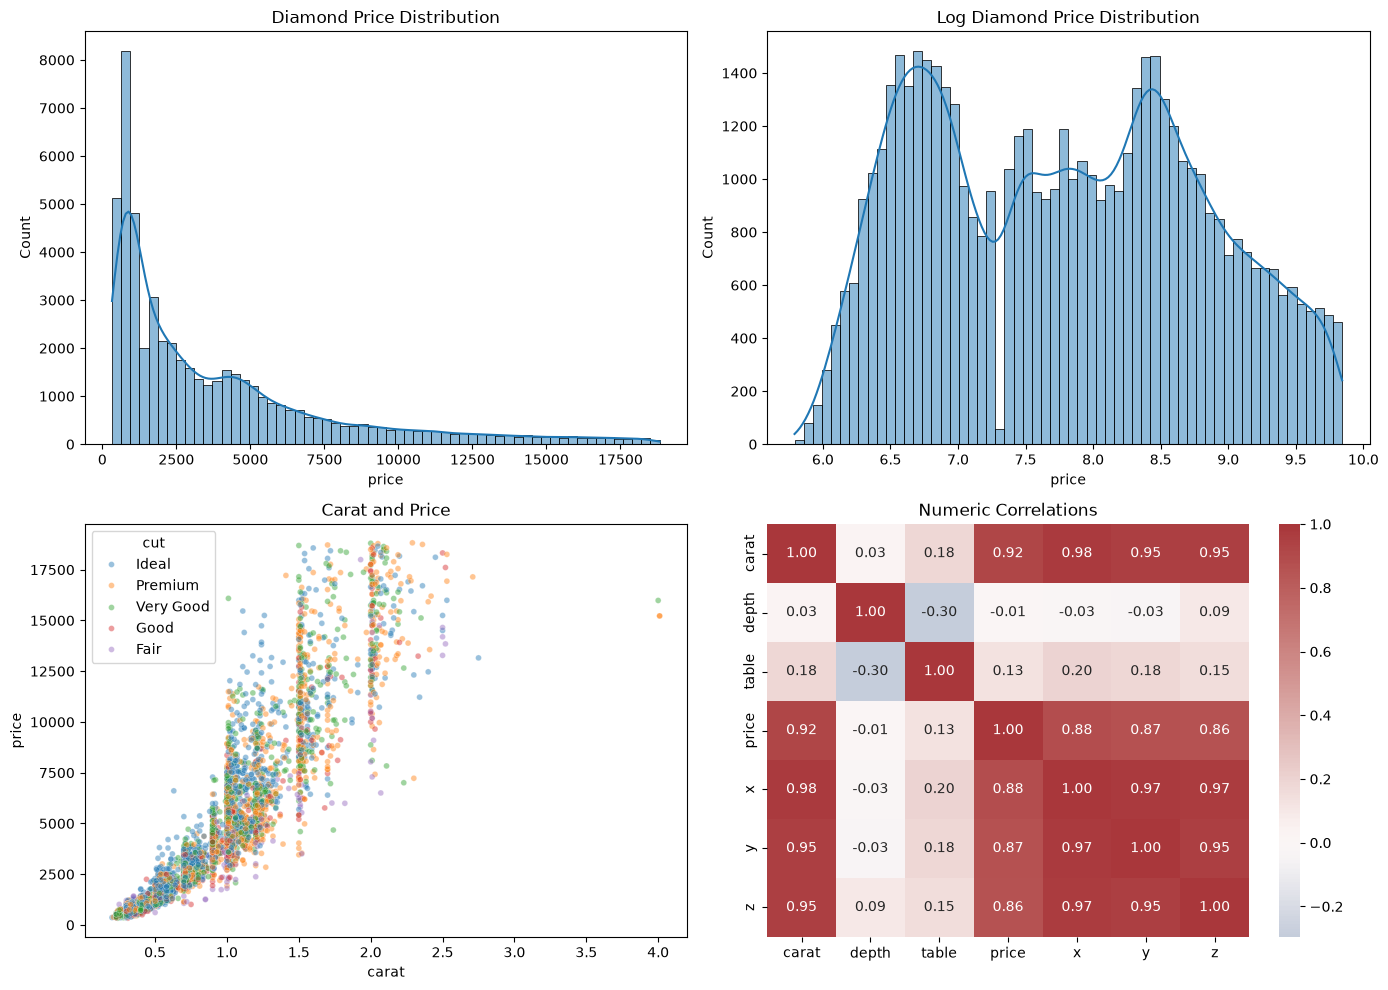

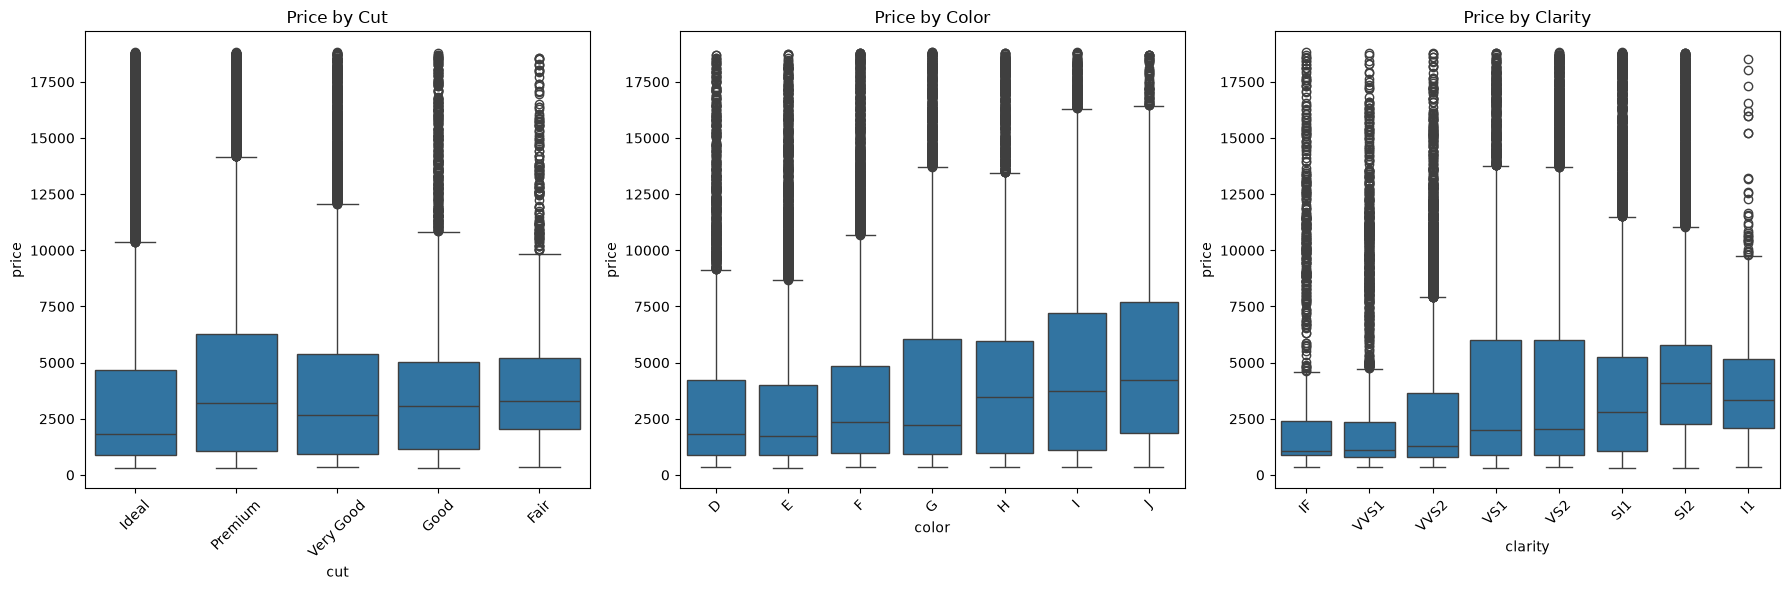

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(diamonds_raw["price"], bins=60, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Diamond Price Distribution")
sns.histplot(np.log1p(diamonds_raw["price"]), bins=60, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Log Diamond Price Distribution")
sns.scatterplot(data=diamonds_raw.sample(6000, random_state=SEED), x="carat", y="price", hue="cut", alpha=0.45, s=18, ax=axes[1, 0])
axes[1, 0].set_title("Carat and Price")
sns.heatmap(diamonds_raw.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1, 1])
axes[1, 1].set_title("Numeric Correlations")
save_figure("01_eda_overview.png")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for axis, feature in zip(axes, CATEGORICAL_FEATURES):
    sns.boxplot(data=diamonds_raw, x=feature, y="price", ax=axis)
    axis.tick_params(axis="x", rotation=45)
    axis.set_title(f"Price by {feature.title()}")
save_figure("02_categorical_price_relationships.png")


In [10]:
valid_dimensions = (diamonds_raw[["x", "y", "z"]] > 0).all(axis=1)
valid_geometry = (diamonds_raw["y"] < 20) & (diamonds_raw["z"] < 20)
valid_table = diamonds_raw["table"] < 80
diamonds = diamonds_raw.loc[valid_dimensions & valid_geometry & valid_table].drop_duplicates().reset_index(drop=True)
print({"raw_rows": len(diamonds_raw), "clean_rows": len(diamonds), "removed_rows": len(diamonds_raw) - len(diamonds)})
print(diamonds.describe(include="all").transpose())

train_validation_data, test_data = train_test_split(diamonds, test_size=0.20, random_state=SEED)
train_data, validation_data = train_test_split(train_validation_data, test_size=0.20, random_state=SEED)
train_data = train_data.reset_index(drop=True)
validation_data = validation_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)
print({"train_rows": len(train_data), "validation_rows": len(validation_data), "test_rows": len(test_data)})

preprocessor = ColumnTransformer(
    [
        ("numeric", StandardScaler(), NUMERICAL_FEATURES),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ],
    remainder="drop",
)
X_train = preprocessor.fit_transform(train_data[FEATURES]).astype(np.float32)
X_validation = preprocessor.transform(validation_data[FEATURES]).astype(np.float32)
X_test = preprocessor.transform(test_data[FEATURES]).astype(np.float32)
y_train = train_data["price"].to_numpy(dtype=np.float64)
y_validation = validation_data["price"].to_numpy(dtype=np.float64)
y_test = test_data["price"].to_numpy(dtype=np.float64)
print({"input_features": X_train.shape[1], "train_shape": X_train.shape, "validation_shape": X_validation.shape, "test_shape": X_test.shape})


{'raw_rows': 53940, 'clean_rows': 53771, 'removed_rows': 169}
           count unique    top   freq         mean          std    min    25%  \
carat    53771.0    NaN    NaN    NaN     0.797502     0.473126    0.2    0.4   
cut        53771      5  Ideal  21484          NaN          NaN    NaN    NaN   
color      53771      7      G  11254          NaN          NaN    NaN    NaN   
clarity    53771      8    SI1  13029          NaN          NaN    NaN    NaN   
depth    53771.0    NaN    NaN    NaN    61.748342     1.429575   43.0   61.0   
table    53771.0    NaN    NaN    NaN    57.457213     2.227406   43.0   56.0   
price    53771.0    NaN    NaN    NaN  3930.961466  3985.681461  326.0  951.0   
x        53771.0    NaN    NaN    NaN     5.731509     1.118544   3.73   4.71   
y        53771.0    NaN    NaN    NaN     5.733398     1.110455   3.68   4.72   
z        53771.0    NaN    NaN    NaN       3.5393     0.691051   1.07   2.91   

            50%     75%      max  
carat      

In [11]:
common = {"epochs": 80, "batch_size": 256, "patience": 8, "min_delta": 1e-5, "dropout": 0.0, "weight_decay": 0.0, "lr": 0.001, "target": "raw"}
experiment_configs = [
    {**common, "name": "E01_SNN_16_RAW", "layers": [16]},
    {**common, "name": "E02_SNN_32_RAW", "layers": [32]},
    {**common, "name": "E03_SNN_64_RAW", "layers": [64]},
    {**common, "name": "E04_SNN_128_RAW", "layers": [128]},
    {**common, "name": "E05_DNN_64_32_RAW", "layers": [64, 32]},
    {**common, "name": "E06_DNN_128_64_RAW", "layers": [128, 64]},
    {**common, "name": "E07_DNN_128_64_32_RAW", "layers": [128, 64, 32]},
    {**common, "name": "E08_DNN_128_64_32_LOG", "layers": [128, 64, 32], "target": "log"},
    {**common, "name": "E09_DNN_128_64_32_LOG_LR0003", "layers": [128, 64, 32], "target": "log", "lr": 0.0003},
    {**common, "name": "E10_DNN_256_128_64_LOG_DROPOUT", "layers": [256, 128, 64], "target": "log", "dropout": 0.15, "weight_decay": 1e-5},
]


In [12]:
results = []
predictions = pd.DataFrame({"actual_price": y_test})
validation_predictions = pd.DataFrame({"actual_price": y_validation})
models = {}
target_scalers = {}
histories = {}

for index, config in enumerate(experiment_configs, start=1):
    started = time.perf_counter()
    scaler = fit_target_scaler(y_train, config["target"])
    y_train_scaled = transform_target(y_train, scaler)
    y_validation_scaled = transform_target(y_validation, scaler)
    model, history, best_epoch = fit_regressor(X_train, y_train_scaled, X_validation, y_validation_scaled, config, SEED + index)
    y_validation_predicted = predict_regressor(model, X_validation, scaler)
    y_test_predicted = predict_regressor(model, X_test, scaler)
    validation_result = regression_metrics(y_validation, y_validation_predicted)
    test_result = regression_metrics(y_test, y_test_predicted)
    elapsed = time.perf_counter() - started
    parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    category = "SNN" if len(config["layers"]) == 1 else "DNN"
    results.append(experiment_row(config["name"], category, config["layers"], config["target"], config["lr"], config["batch_size"], config["dropout"], parameters, best_epoch, elapsed, validation_result, test_result))
    predictions[config["name"]] = y_test_predicted
    validation_predictions[config["name"]] = y_validation_predicted
    models[config["name"]] = model.to("cpu")
    target_scalers[config["name"]] = scaler
    histories[config["name"]] = history
    print(results[-1])


{'Experiment': 'E01_SNN_16_RAW', 'Category': 'SNN', 'Layers': '16', 'Target': 'raw', 'Learning_Rate': 0.001, 'Batch_Size': 256, 'Dropout': 0.0, 'Parameters': 401, 'Best_Epoch': 73, 'Seconds': 17.700108040997293, 'Validation_MAE': 306.83129667032347, 'Validation_RMSE': 560.543245416577, 'Validation_MAPE': 9.276317847234475, 'Validation_R2': 0.9800330100811382, 'Validation_P95_APE': 25.528122082952294, 'Validation_Within_20_Pct': 89.85355648535564, 'Test_MAE': 308.70180735660546, 'Test_RMSE': 565.6876944495949, 'Test_MAPE': 9.512039091682615, 'Test_R2': 0.9794585191652723, 'Test_P95_APE': 25.89073791258256, 'Test_Within_20_Pct': 89.2701069270107, 'MAPE_Goal_Met': False, 'Coverage_Goal_Met': False}
{'Experiment': 'E02_SNN_32_RAW', 'Category': 'SNN', 'Layers': '32', 'Target': 'raw', 'Learning_Rate': 0.001, 'Batch_Size': 256, 'Dropout': 0.0, 'Parameters': 801, 'Best_Epoch': 76, 'Seconds': 15.261807666014647, 'Validation_MAE': 301.14883449106577, 'Validation_RMSE': 550.31195186827, 'Validati

In [13]:
base_results = pd.DataFrame(results)
best_base_name = base_results.sort_values(["Validation_MAPE", "Validation_MAE"]).iloc[0]["Experiment"]
best_base_config = next(config for config in experiment_configs if config["name"] == best_base_name)
print({"best_base_model": best_base_name})

low_threshold, high_threshold = np.quantile(y_train, [1 / 3, 2 / 3])
tier_train = np.digitize(y_train, [low_threshold, high_threshold], right=True).astype(np.int64)
tier_validation = np.digitize(y_validation, [low_threshold, high_threshold], right=True).astype(np.int64)
tier_test = np.digitize(y_test, [low_threshold, high_threshold], right=True).astype(np.int64)
print({"low_threshold": float(low_threshold), "high_threshold": float(high_threshold)})
print(pd.Series(tier_train).value_counts().sort_index())


{'best_base_model': 'E10_DNN_256_128_64_LOG_DROPOUT'}
{'low_threshold': 1235.0, 'high_threshold': 4284.666666666664}
0    11486
1    11455
2    11471
Name: count, dtype: int64


In [14]:
classifier_config = {"layers": [128, 64, 32], "dropout": 0.10, "lr": 0.001, "weight_decay": 1e-5, "batch_size": 256, "epochs": 80, "patience": 8, "min_delta": 1e-5}
classifier_started = time.perf_counter()
classifier, classifier_history, classifier_best_epoch = fit_classifier(X_train, tier_train, X_validation, tier_validation, classifier_config, SEED + 100)
validation_tier_probabilities = predict_classifier(classifier, X_validation)
test_tier_probabilities = predict_classifier(classifier, X_test)
validation_tier_predictions = validation_tier_probabilities.argmax(axis=1)
test_tier_predictions = test_tier_probabilities.argmax(axis=1)
print({"classifier_validation_accuracy": float(accuracy_score(tier_validation, validation_tier_predictions)), "classifier_test_accuracy": float(accuracy_score(tier_test, test_tier_predictions)), "classifier_best_epoch": classifier_best_epoch})


{'classifier_validation_accuracy': 0.9573454207345421, 'classifier_test_accuracy': 0.9542538354253836, 'classifier_best_epoch': 39}


In [15]:
tier_config = {"layers": [128, 64, 32], "dropout": 0.0, "lr": 0.001, "weight_decay": 0.0, "batch_size": 256, "epochs": 100, "patience": 10, "min_delta": 1e-5, "target": "log"}
tier_models = {}
tier_scalers = {}
tier_histories = {}
validation_tier_price_predictions = np.zeros((len(y_validation), 3), dtype=np.float64)
test_tier_price_predictions = np.zeros((len(y_test), 3), dtype=np.float64)

for tier in range(3):
    train_mask = tier_train == tier
    validation_mask = tier_validation == tier
    scaler = fit_target_scaler(y_train[train_mask], tier_config["target"])
    model, history, best_epoch = fit_regressor(
        X_train[train_mask],
        transform_target(y_train[train_mask], scaler),
        X_validation[validation_mask],
        transform_target(y_validation[validation_mask], scaler),
        tier_config,
        SEED + 200 + tier,
    )
    tier_models[tier] = model
    tier_scalers[tier] = scaler
    tier_histories[tier] = history
    validation_tier_price_predictions[:, tier] = predict_regressor(model, X_validation, scaler)
    test_tier_price_predictions[:, tier] = predict_regressor(model, X_test, scaler)
    true_tier_validation_metrics = regression_metrics(y_validation[validation_mask], validation_tier_price_predictions[validation_mask, tier])
    print({"tier": tier, "train_rows": int(train_mask.sum()), "validation_rows": int(validation_mask.sum()), "best_epoch": best_epoch, **true_tier_validation_metrics})


{'tier': 0, 'train_rows': 11486, 'validation_rows': 2794, 'best_epoch': 49, 'MAE': 49.45057653505276, 'RMSE': 65.98933067394438, 'MAPE': 6.423355257182168, 'R2': 0.905105242542814, 'P95_APE': 16.413361442763073, 'Within_20_Pct': 97.13672154617036, 'MAPE_Goal_Met': False, 'Coverage_Goal_Met': True}
{'tier': 1, 'train_rows': 11455, 'validation_rows': 2901, 'best_epoch': 46, 'MAE': 155.94717815953746, 'RMSE': 220.86188069832238, 'MAPE': 6.237748942779434, 'R2': 0.938000545239374, 'P95_APE': 17.742331929460388, 'Within_20_Pct': 96.82867976559807, 'MAPE_Goal_Met': False, 'Coverage_Goal_Met': True}
{'tier': 2, 'train_rows': 11471, 'validation_rows': 2909, 'best_epoch': 38, 'MAE': 588.5347827113844, 'RMSE': 892.9204733350841, 'MAPE': 6.788825105566993, 'R2': 0.943783271315977, 'P95_APE': 19.389260546827355, 'Within_20_Pct': 95.39360605018908, 'MAPE_Goal_Met': False, 'Coverage_Goal_Met': True}


In [16]:
validation_hard_predictions = validation_tier_price_predictions[np.arange(len(y_validation)), validation_tier_predictions]
test_hard_predictions = test_tier_price_predictions[np.arange(len(y_test)), test_tier_predictions]
validation_soft_predictions = np.sum(validation_tier_price_predictions * validation_tier_probabilities, axis=1)
test_soft_predictions = np.sum(test_tier_price_predictions * test_tier_probabilities, axis=1)
stack_elapsed = time.perf_counter() - classifier_started

hard_validation_metrics = regression_metrics(y_validation, validation_hard_predictions)
hard_test_metrics = regression_metrics(y_test, test_hard_predictions)
soft_validation_metrics = regression_metrics(y_validation, validation_soft_predictions)
soft_test_metrics = regression_metrics(y_test, test_soft_predictions)
stack_parameters = sum(parameter.numel() for parameter in classifier.parameters()) + sum(sum(parameter.numel() for parameter in model.parameters()) for model in tier_models.values())

results.append(experiment_row("E11_STACKUP_HARD_ROUTING", "Stackup", classifier_config["layers"], "log", classifier_config["lr"], classifier_config["batch_size"], classifier_config["dropout"], stack_parameters, classifier_best_epoch, stack_elapsed, hard_validation_metrics, hard_test_metrics))
results.append(experiment_row("E12_STACKUP_SOFT_WEIGHTED", "Stackup", classifier_config["layers"], "log", classifier_config["lr"], classifier_config["batch_size"], classifier_config["dropout"], stack_parameters, classifier_best_epoch, stack_elapsed, soft_validation_metrics, soft_test_metrics))
predictions["E11_STACKUP_HARD_ROUTING"] = test_hard_predictions
predictions["E12_STACKUP_SOFT_WEIGHTED"] = test_soft_predictions
validation_predictions["E11_STACKUP_HARD_ROUTING"] = validation_hard_predictions
validation_predictions["E12_STACKUP_SOFT_WEIGHTED"] = validation_soft_predictions


In [17]:
results_table = pd.DataFrame(results).sort_values(["Validation_MAPE", "Validation_MAE"]).reset_index(drop=True)
results_table.to_csv(OUTPUT_DIR / "experiment_results.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
validation_predictions.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)
print(results_table.to_string(index=False))

best_overall_name = results_table.iloc[0]["Experiment"]
best_test_prediction = predictions[best_overall_name].to_numpy()
best_test_metrics = regression_metrics(y_test, best_test_prediction)
print({"selected_by_validation": best_overall_name, **best_test_metrics})


                    Experiment Category     Layers Target  Learning_Rate  Batch_Size  Dropout  Parameters  Best_Epoch   Seconds  Validation_MAE  Validation_RMSE  Validation_MAPE  Validation_R2  Validation_P95_APE  Validation_Within_20_Pct   Test_MAE  Test_RMSE  Test_MAPE  Test_R2  Test_P95_APE  Test_Within_20_Pct  MAPE_Goal_Met  Coverage_Goal_Met
E10_DNN_256_128_64_LOG_DROPOUT      DNN 256-128-64    log         0.0010         256     0.15       47361          59 17.567426      282.978156       561.489176         6.767309       0.979966           18.821273                 95.943747 282.078573 557.598029   6.905275 0.980042     18.882461           95.574152          False               True
         E08_DNN_128_64_32_LOG      DNN  128-64-32    log         0.0010         256     0.00       13441          61 16.778002      281.140849       548.811191         6.783156       0.980860           18.674909                 95.990237 279.557116 531.803082   6.980875 0.981846     18.710999        

In [18]:
price_group = pd.cut(y_test, bins=[-np.inf, low_threshold, high_threshold, np.inf], labels=["Low", "Medium", "High"])
group_results = []
for experiment in predictions.columns[1:]:
    for group in ["Low", "Medium", "High"]:
        mask = np.asarray(price_group == group)
        group_metrics = regression_metrics(y_test[mask], predictions.loc[mask, experiment].to_numpy())
        group_results.append({"Experiment": experiment, "Price_Tier": group, **group_metrics})
group_results_table = pd.DataFrame(group_results)
group_results_table.to_csv(OUTPUT_DIR / "results_by_price_tier.csv", index=False)
print(group_results_table.to_string(index=False))


                    Experiment Price_Tier        MAE       RMSE      MAPE       R2   P95_APE  Within_20_Pct  MAPE_Goal_Met  Coverage_Goal_Met
                E01_SNN_16_RAW        Low  96.510683 120.111562 12.858025 0.675383 29.876552      80.393258          False              False
                E01_SNN_16_RAW     Medium 217.793752 322.678236  8.476305 0.869279 22.425554      93.070392          False              False
                E01_SNN_16_RAW       High 615.503645 921.605722  7.217952 0.941107 21.416390      94.272009          False              False
                E02_SNN_32_RAW        Low 100.491311 122.511114 13.486969 0.662283 31.660275      79.438202          False              False
                E02_SNN_32_RAW     Medium 213.670987 315.295673  8.346173 0.875192 22.455638      93.234730          False              False
                E02_SNN_32_RAW       High 599.623139 887.851581  7.119154 0.945342 19.949988      95.033860          False               True
      

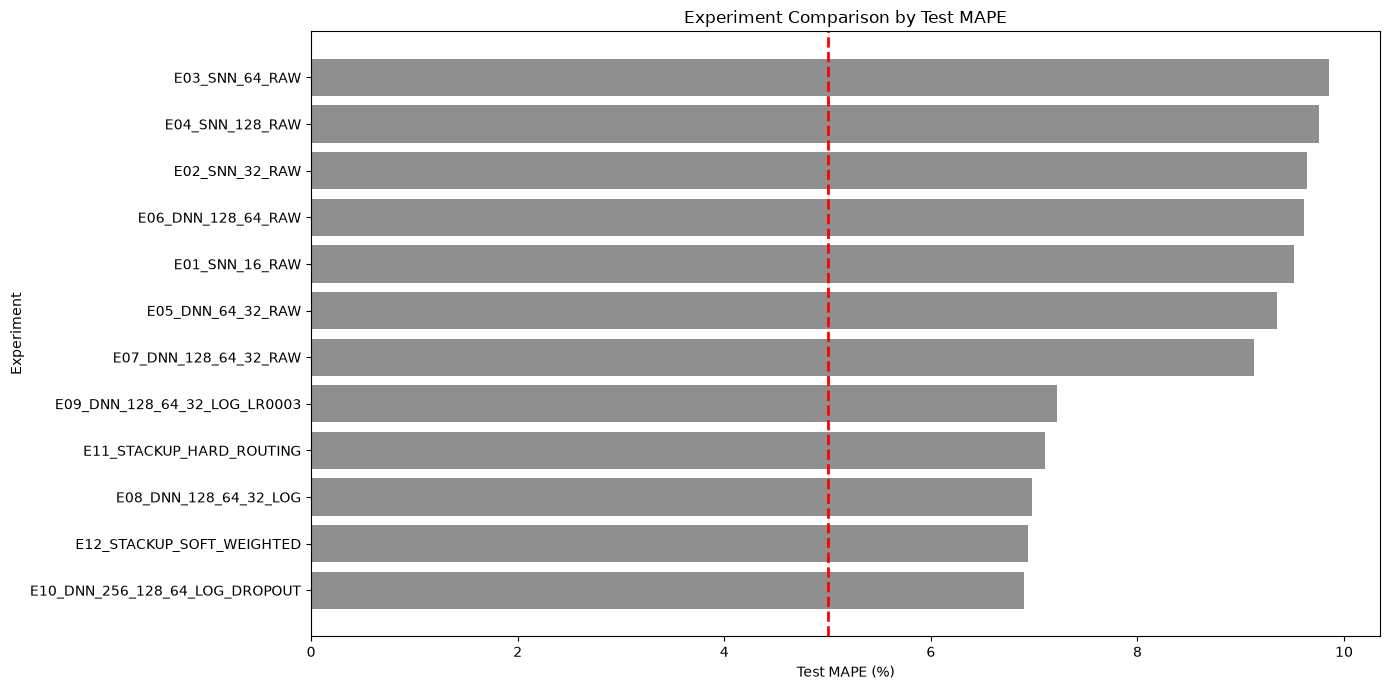

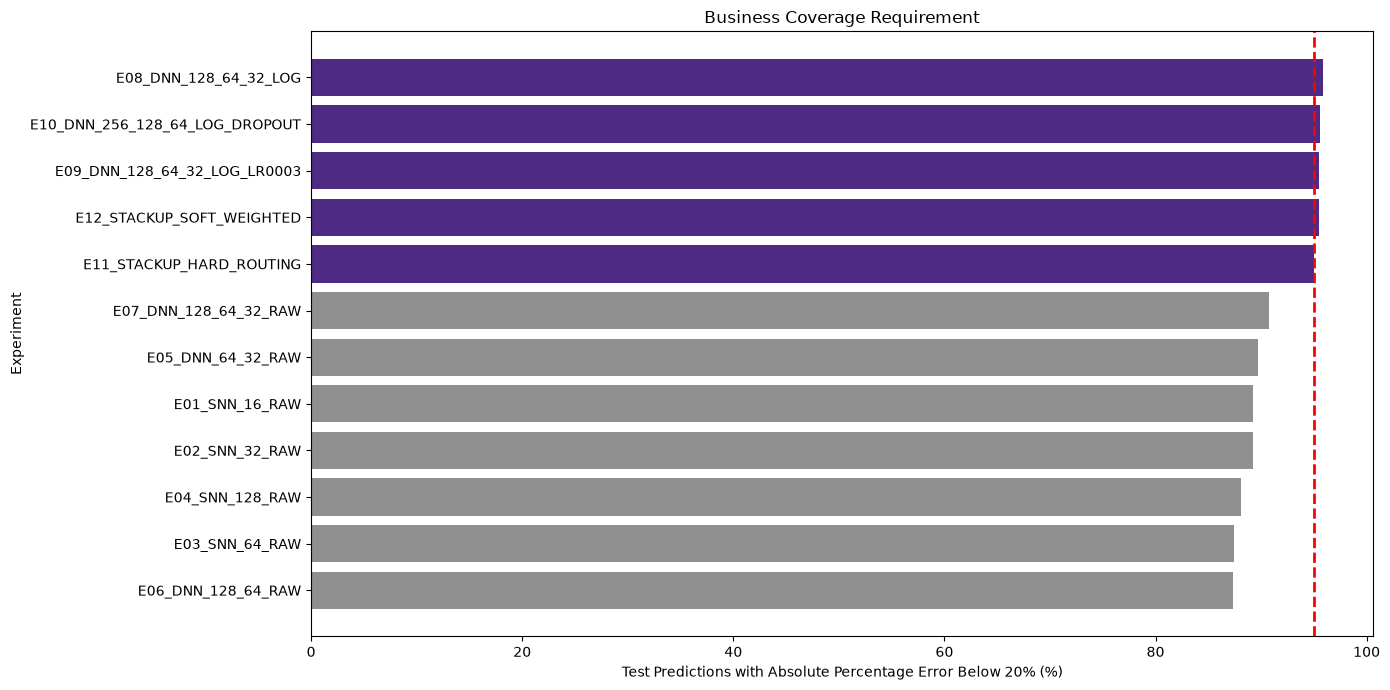

In [19]:
plt.figure(figsize=(14, 7))
ordered = results_table.sort_values("Test_MAPE")
colors = ["#4E2A84" if value <= 5 else "#8F8F8F" for value in ordered["Test_MAPE"]]
plt.barh(ordered["Experiment"], ordered["Test_MAPE"], color=colors)
plt.axvline(5, color="red", linestyle="--", linewidth=2)
plt.xlabel("Test MAPE (%)")
plt.ylabel("Experiment")
plt.title("Experiment Comparison by Test MAPE")
save_figure("03_experiment_mape_comparison.png")

plt.figure(figsize=(14, 7))
ordered = results_table.sort_values("Test_Within_20_Pct")
colors = ["#4E2A84" if value >= 95 else "#8F8F8F" for value in ordered["Test_Within_20_Pct"]]
plt.barh(ordered["Experiment"], ordered["Test_Within_20_Pct"], color=colors)
plt.axvline(95, color="red", linestyle="--", linewidth=2)
plt.xlabel("Test Predictions with Absolute Percentage Error Below 20% (%)")
plt.ylabel("Experiment")
plt.title("Business Coverage Requirement")
save_figure("04_experiment_coverage_comparison.png")


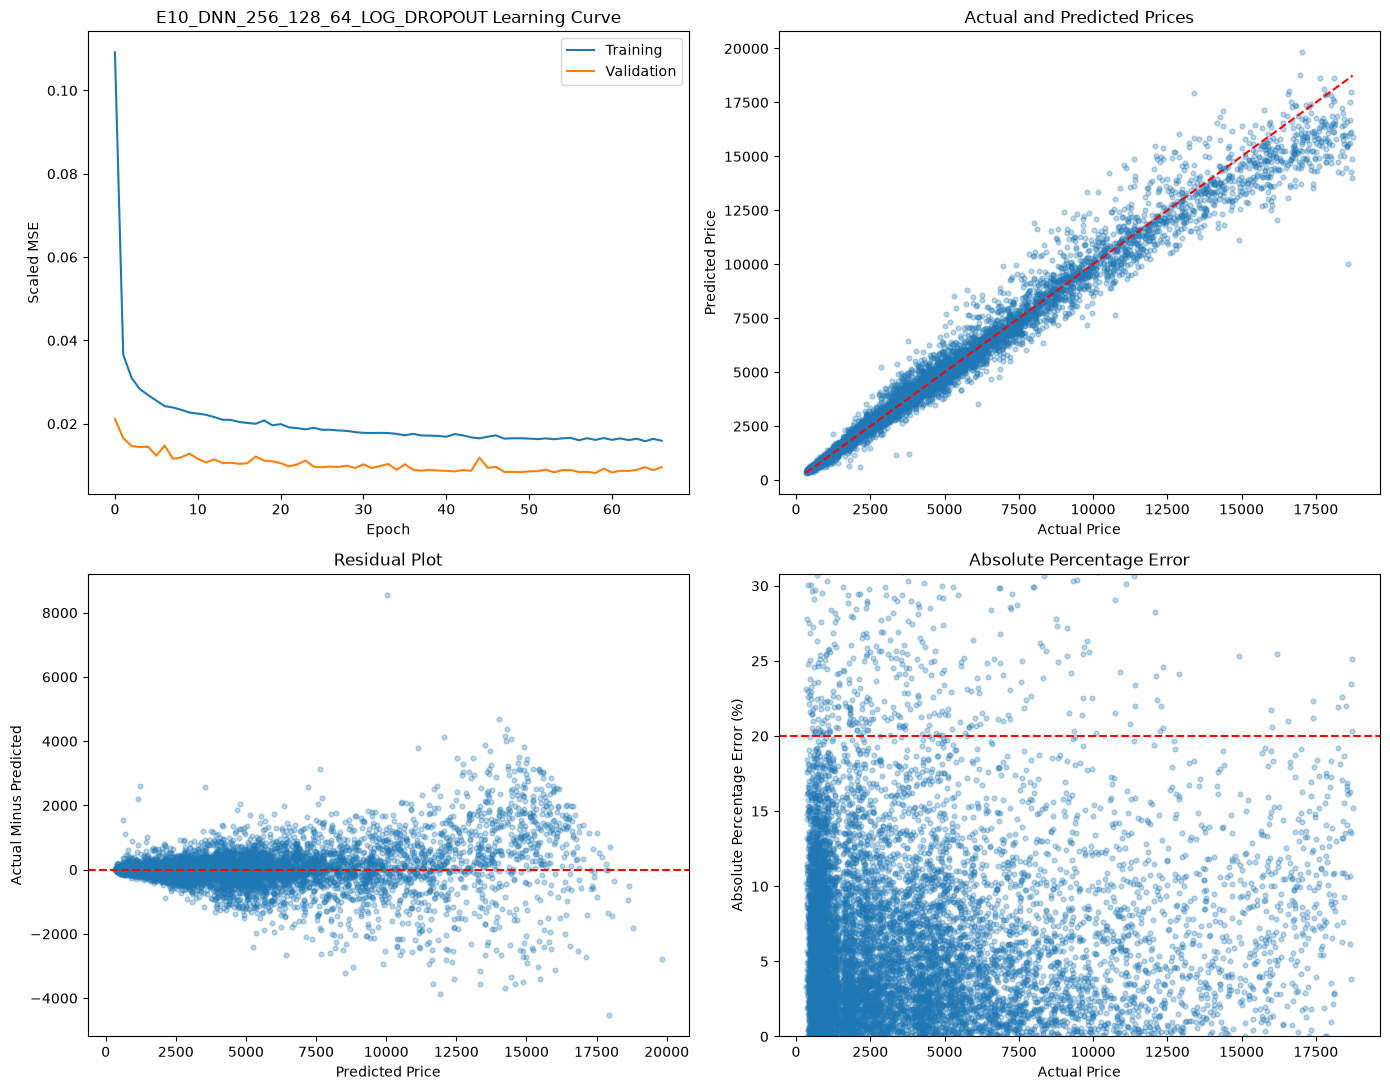

In [20]:
best_history = histories[best_base_name]
best_base_test_prediction = predictions[best_base_name].to_numpy()
best_base_errors = y_test - best_base_test_prediction
best_base_absolute_percentage_error = np.abs(best_base_errors / y_test) * 100
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes[0, 0].plot(best_history["loss"], label="Training")
axes[0, 0].plot(best_history["val_loss"], label="Validation")
axes[0, 0].set_title(f"{best_base_name} Learning Curve")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Scaled MSE")
axes[0, 0].legend()
axes[0, 1].scatter(y_test, best_base_test_prediction, alpha=0.30, s=12)
axes[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--")
axes[0, 1].set_title("Actual and Predicted Prices")
axes[0, 1].set_xlabel("Actual Price")
axes[0, 1].set_ylabel("Predicted Price")
axes[1, 0].scatter(best_base_test_prediction, best_base_errors, alpha=0.30, s=12)
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot")
axes[1, 0].set_xlabel("Predicted Price")
axes[1, 0].set_ylabel("Actual Minus Predicted")
axes[1, 1].scatter(y_test, best_base_absolute_percentage_error, alpha=0.30, s=12)
axes[1, 1].axhline(20, color="red", linestyle="--")
axes[1, 1].set_ylim(0, min(100, np.percentile(best_base_absolute_percentage_error, 99)))
axes[1, 1].set_title("Absolute Percentage Error")
axes[1, 1].set_xlabel("Actual Price")
axes[1, 1].set_ylabel("Absolute Percentage Error (%)")
save_figure("05_best_base_model_diagnostics.png")


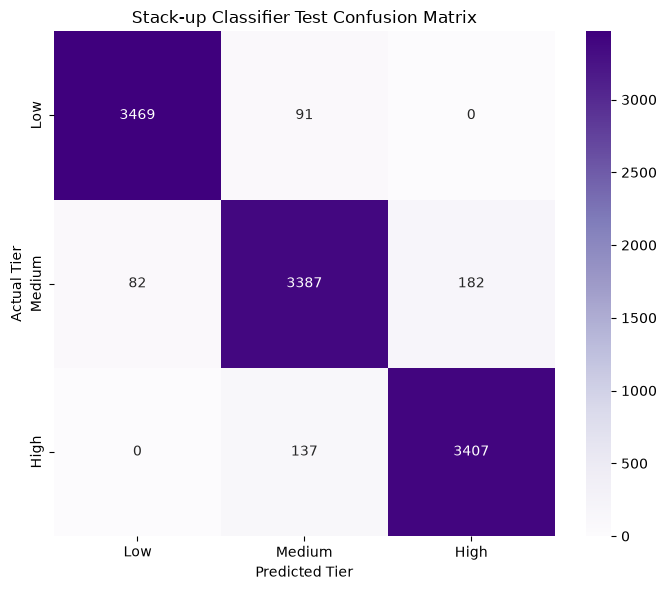

In [21]:
cm = confusion_matrix(tier_test, test_tier_predictions)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=["Low", "Medium", "High"], yticklabels=["Low", "Medium", "High"])
plt.xlabel("Predicted Tier")
plt.ylabel("Actual Tier")
plt.title("Stack-up Classifier Test Confusion Matrix")
save_figure("06_stackup_confusion_matrix.png")


/var/folders/lj/1k_g_vgj15d35ld6vr4ms6000000gn/T/ipykernel_75449/3820536961.py:9: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


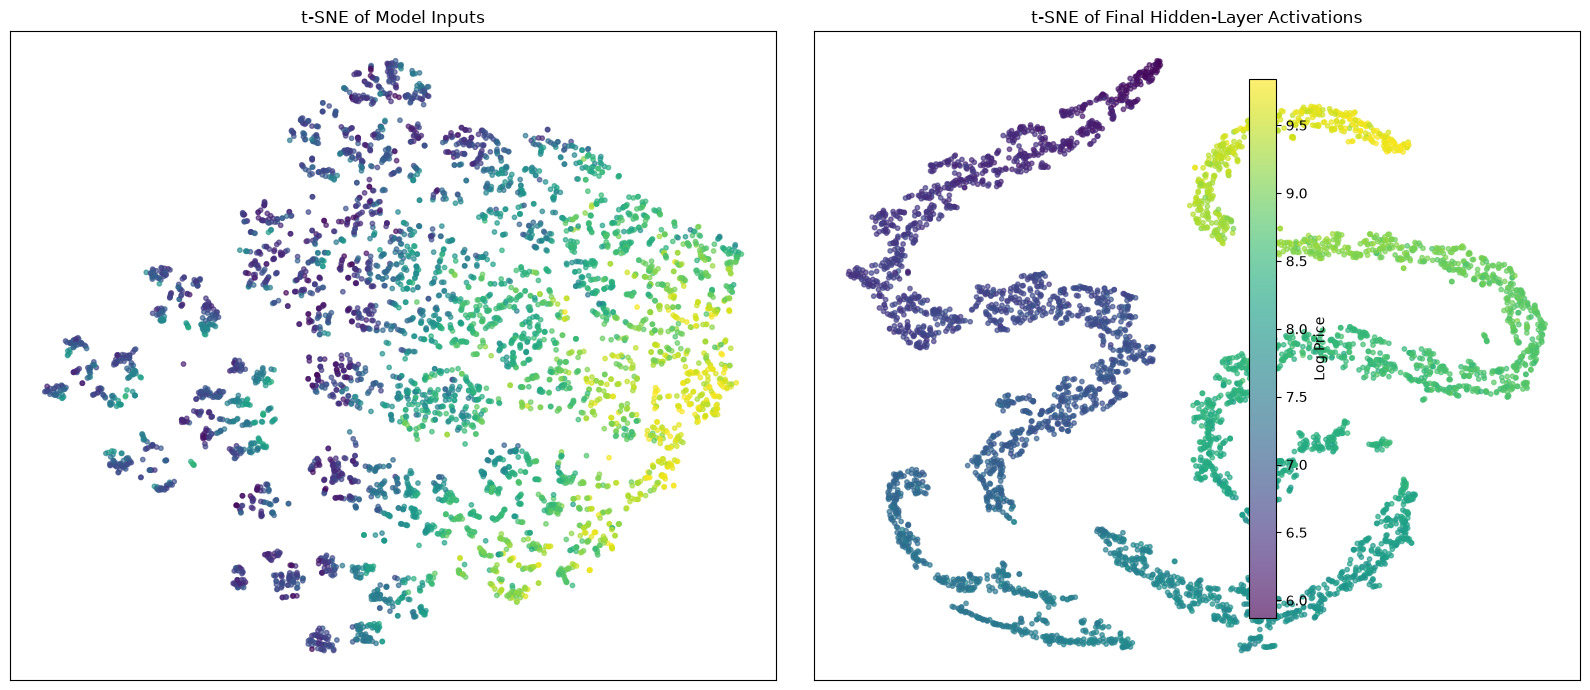

In [22]:
sample_size = min(5000, len(X_train))
sample_indices = np.random.default_rng(SEED).choice(len(X_train), size=sample_size, replace=False)
X_tsne = X_train[sample_indices]
y_tsne = y_train[sample_indices]
best_base_model = models[best_base_name].to(DEVICE)
feature_extractor = nn.Sequential(*list(best_base_model.children())[:-1]).to(DEVICE)
feature_extractor.eval()
with torch.no_grad():
    hidden_activations = feature_extractor(torch.as_tensor(X_tsne, dtype=torch.float32).to(DEVICE)).cpu().numpy()
input_embedding = TSNE(n_components=2, perplexity=30, learning_rate="auto", init="pca", max_iter=1000, random_state=SEED).fit_transform(X_tsne)
hidden_embedding = TSNE(n_components=2, perplexity=30, learning_rate="auto", init="pca", max_iter=1000, random_state=SEED).fit_transform(hidden_activations)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
input_plot = axes[0].scatter(input_embedding[:, 0], input_embedding[:, 1], c=np.log1p(y_tsne), cmap="viridis", s=10, alpha=0.65)
axes[0].set_title("t-SNE of Model Inputs")
axes[0].set_xticks([])
axes[0].set_yticks([])
hidden_plot = axes[1].scatter(hidden_embedding[:, 0], hidden_embedding[:, 1], c=np.log1p(y_tsne), cmap="viridis", s=10, alpha=0.65)
axes[1].set_title("t-SNE of Final Hidden-Layer Activations")
axes[1].set_xticks([])
axes[1].set_yticks([])
fig.colorbar(hidden_plot, ax=axes, label="Log Price")
save_figure("07_tsne_input_and_hidden_representations.png")


In [23]:
torch.save({"model_state": models[best_base_name].state_dict(), "configuration": best_base_config, "target_scaler": target_scalers[best_base_name], "input_features": X_train.shape[1]}, OUTPUT_DIR / "best_base_model.pt")
torch.save({"classifier_state": classifier.to("cpu").state_dict(), "classifier_configuration": classifier_config, "tier_model_states": {tier: model.to("cpu").state_dict() for tier, model in tier_models.items()}, "tier_configuration": tier_config, "tier_scalers": tier_scalers, "low_threshold": float(low_threshold), "high_threshold": float(high_threshold), "input_features": X_train.shape[1]}, OUTPUT_DIR / "stackup_models.pt")

summary = {
    "seed": SEED,
    "device": str(DEVICE),
    "raw_rows": len(diamonds_raw),
    "clean_rows": len(diamonds),
    "train_rows": len(train_data),
    "validation_rows": len(validation_data),
    "test_rows": len(test_data),
    "encoded_input_features": int(X_train.shape[1]),
    "low_threshold": float(low_threshold),
    "high_threshold": float(high_threshold),
    "classifier_validation_accuracy": float(accuracy_score(tier_validation, validation_tier_predictions)),
    "classifier_test_accuracy": float(accuracy_score(tier_test, test_tier_predictions)),
    "selected_model": best_overall_name,
    "selected_model_test_metrics": best_test_metrics,
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))


{
  "seed": 42,
  "device": "mps",
  "raw_rows": 53940,
  "clean_rows": 53771,
  "train_rows": 34412,
  "validation_rows": 8604,
  "test_rows": 10755,
  "encoded_input_features": 23,
  "low_threshold": 1235.0,
  "high_threshold": 4284.666666666664,
  "classifier_validation_accuracy": 0.9573454207345421,
  "classifier_test_accuracy": 0.9542538354253836,
  "selected_model": "E10_DNN_256_128_64_LOG_DROPOUT",
  "selected_model_test_metrics": {
    "MAE": 282.0785728101476,
    "RMSE": 557.5980291301869,
    "MAPE": 6.905275417589025,
    "R2": 0.9800418287054524,
    "P95_APE": 18.88246096612115,
    "Within_20_Pct": 95.57415155741515,
    "MAPE_Goal_Met": false,
    "Coverage_Goal_Met": true
  }
}
